## 1. Data Understanding

### Dataset Description

The SECOM dataset contains measurements collected
from a semiconductor manufacturing process.

The objective is to investigate whether manufacturing
measurements can help predict product quality failures.


In [19]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from IPython.display import display

SEED = 42
rng = np.random.default_rng(SEED)

DATA_DIR = Path("../secom_data/raw")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
PASS_COL, FAIL_COL = "#4C78A8", "#E45756"
MISSING_THRESHOLD = 40  # % missing above which a feature is considered unusable


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [20]:
data_path = DATA_DIR / "secom.data"
labels_path = DATA_DIR / "secom_labels.data"

# Load data
X_raw = pd.read_csv(data_path, sep=r"\s+", header=None)
y_raw = pd.read_csv(labels_path, sep=r"\s+", header=None)

y = y_raw.iloc[:,0]
y = (y == 1).astype(int) 
ts = pd.to_datetime(y_raw[1], format="%d/%m/%Y %H:%M:%S")

# Sanity checks against the dataset documentation
assert X_raw.shape == (1567, 590), X_raw.shape
assert y.sum() == 104, y.sum()

print(f"Observations: {X_raw.shape[0]}  |  Features: {X_raw.shape[1]}")
print(f"Failures: {y.sum()}  |  Passes: {(y == 0).sum()}")
print(f"Duplicate rows: {X_raw.duplicated().sum()}")
print(f"Missing values: {int(X_raw.isna().sum().sum())} "
      f"({X_raw.isna().sum().sum() / X_raw.size * 100:.2f}% of all cells)")
print(ts.min(), ts.max())

Observations: 1567  |  Features: 590
Failures: 104  |  Passes: 1463
Duplicate rows: 0
Missing values: 41951 (4.54% of all cells)
2008-07-19 11:55:00 2008-10-17 06:07:00


### Train test split

In [21]:
# Sort chronologically
order = np.argsort(ts_all.values, kind="stable")
X = X_raw.iloc[order].reset_index(drop=True)
y = y.iloc[order].reset_index(drop=True)
ts = ts.iloc[order].reset_index(drop=True)

# Temporal split: earliest 80% = train, latest 20% = test
split = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print(f"Date range: {ts.min()}  ->  {ts.max()}")
print(f"Train: {len(X_train)} rows, {y_train.sum()} failures ({y_train.mean() * 100:.2f}%)  "
      f"[{ts.iloc[0].date()} to {ts.iloc[split - 1].date()}]")
print(f"Test:  {len(X_test)} rows, {y_test.sum()} failures ({y_test.mean() * 100:.2f}%)  "
      f"[{ts.iloc[split].date()} to {ts.iloc[-1].date()}]")

gaps = ts.diff().dropna()
print(f"Largest gap between consecutive records: {gaps.max()}")

Date range: 2008-07-19 11:55:00  ->  2008-10-17 06:07:00
Train: 1253 rows, 87 failures (6.94%)  [2008-07-19 to 2008-10-02]
Test:  314 rows, 17 failures (5.41%)  [2008-10-02 to 2008-10-17]
Largest gap between consecutive records: 2 days 00:38:00


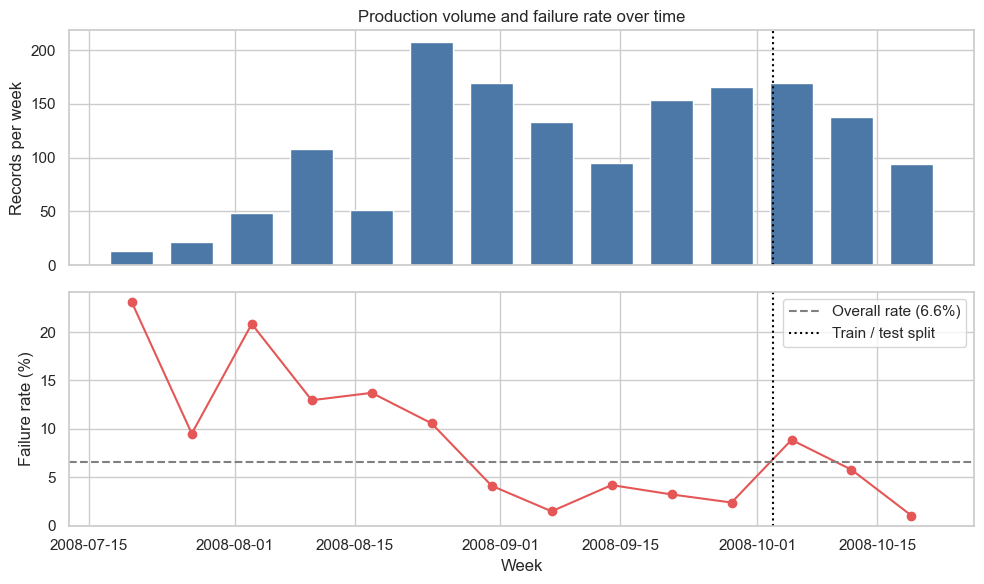

In [22]:
PASS_COL, FAIL_COL = "#4C78A8", "#E45756"  

weekly = (
    pd.DataFrame({"y": y.values}, index=pd.DatetimeIndex(ts.values))
    .resample("W")["y"].agg(["count", "sum", "mean"])
)
weekly.columns = ["records", "failures", "failure_rate"]

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].bar(weekly.index, weekly["records"], width=5, color=PASS_COL)
ax[0].set_ylabel("Records per week")
ax[0].set_title("Production volume and failure rate over time")

ax[1].plot(weekly.index, weekly["failure_rate"] * 100, marker="o", color=FAIL_COL)
ax[1].axhline(y.mean() * 100, ls="--", color="grey", label=f"Overall rate ({y.mean() * 100:.1f}%)")
ax[1].set_ylabel("Failure rate (%)")
ax[1].set_xlabel("Week")

for a in ax:
    a.axvline(ts.iloc[split], color="black", ls=":", label="Train / test split" if a is ax[1] else None)
ax[1].legend()
savefig("02_failures_over_time")

### Missing values

In [23]:
miss_pct = X.isna().mean() * 100

print("Features by missingness level:")
for t in (0, 10, 20, 40, 50, 60):
    print(f"  > {t:>2}% missing: {(miss_pct > t).sum():>3} features")
print(f"\nWorst feature: {miss_pct.idxmax()} ({miss_pct.max():.1f}% missing)")

Features by missingness level:
  >  0% missing: 538 features
  > 10% missing:  52 features
  > 20% missing:  32 features
  > 40% missing:  32 features
  > 50% missing:  28 features
  > 60% missing:  24 features

Worst feature: 157 (91.2% missing)


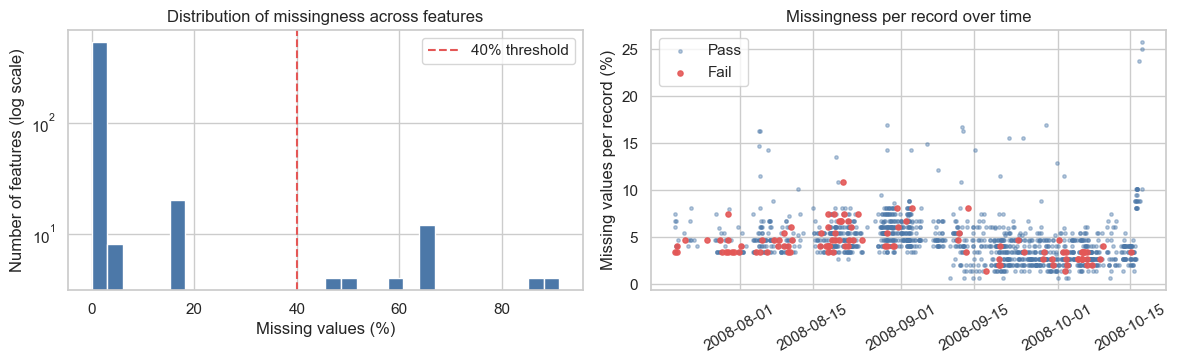

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))

ax[0].hist(miss_pct, bins=30, color=PASS_COL, edgecolor="white")
ax[0].axvline(MISSING_THRESHOLD, color=FAIL_COL, ls="--", label=f"{MISSING_THRESHOLD}% threshold")
ax[0].set_yscale("log")
ax[0].set_xlabel("Missing values (%)")
ax[0].set_ylabel("Number of features (log scale)")
ax[0].set_title("Distribution of missingness across features")
ax[0].legend()

# Missingness per record over time: bursts suggest sensor outages or process changes
row_miss = X.isna().mean(axis=1) * 100
ax[1].scatter(ts[y == 0], row_miss[y == 0], s=6, alpha=0.4, color=PASS_COL, label="Pass")
ax[1].scatter(ts[y == 1], row_miss[y == 1], s=14, alpha=0.9, color=FAIL_COL, label="Fail")
ax[1].set_ylabel("Missing values per record (%)")
ax[1].set_title("Missingness per record over time")
ax[1].tick_params(axis="x", rotation=30)
ax[1].legend()
savefig("03_missing_values")

Features with >=5% missing in train: 52


,pass_missing_%,fail_missing_%,diff
72,47.3,26.4,-20.8
73,47.3,26.4,-20.8
346,47.3,26.4,-20.8
345,47.3,26.4,-20.8
112,34.6,20.7,-14.0
247,34.6,20.7,-14.0
519,34.6,20.7,-14.0
385,34.6,20.7,-14.0
578,63.5,55.2,-8.3
579,63.5,55.2,-8.3


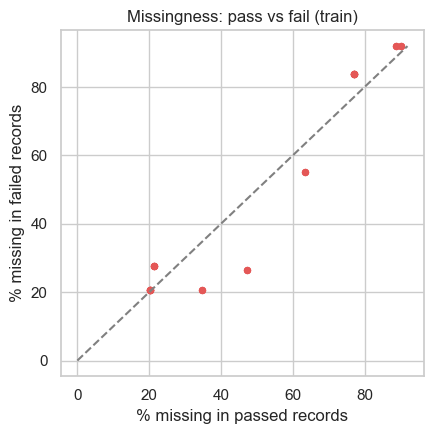

In [25]:
miss_pct_train = X_train.isna().mean() * 100
cand = miss_pct_train[miss_pct_train >= 5].index

rate = pd.DataFrame({
    "pass_missing_%": X_train.loc[y_train == 0, cand].isna().mean() * 100,
    "fail_missing_%": X_train.loc[y_train == 1, cand].isna().mean() * 100,
})
rate["diff"] = rate["fail_missing_%"] - rate["pass_missing_%"]

print(f"Features with >=5% missing in train: {len(cand)}")
display(rate.reindex(rate["diff"].abs().sort_values(ascending=False).index).head(10).round(1))

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(rate["pass_missing_%"], rate["fail_missing_%"], s=18, alpha=0.7, color=FAIL_COL)
lim = max(rate.max().max(), 1)
ax.plot([0, lim], [0, lim], color="grey", ls="--")
ax.set_xlabel("% missing in passed records")
ax.set_ylabel("% missing in failed records")
ax.set_title("Missingness: pass vs fail (train)")
savefig("03_missingness_pass_vs_fail")

### Constant features

In [26]:
nuniq = X.nunique(dropna=True)
constant = nuniq[nuniq <= 1].index
low_card = nuniq[(nuniq > 1) & (nuniq <= 5)].index


def top_value_share(s):
    s = s.dropna()
    return s.value_counts(normalize=True).iloc[0] if len(s) else np.nan


top_share = X.apply(top_value_share)
near_constant = top_share[(top_share > 0.99) & (nuniq > 1)].index

print(f"Constant features (<=1 unique value):           {len(constant)}")
print(f"Near-constant (one value in >99% of records):   {len(near_constant)}")
print(f"Low cardinality (2-5 unique values):            {len(low_card)}")

# Features that are usable for modelling at all (target-independent definition)
usable = [c for c in X.columns if c not in constant and miss_pct[c] <= MISSING_THRESHOLD]
print(f"\nUsable features (non-constant, <= {MISSING_THRESHOLD}% missing): {len(usable)} of {X.shape[1]}")

Constant features (<=1 unique value):           116
Near-constant (one value in >99% of records):   6
Low cardinality (2-5 unique values):            6

Usable features (non-constant, <= 40% missing): 442 of 590


### Scale, Skewness and outliers

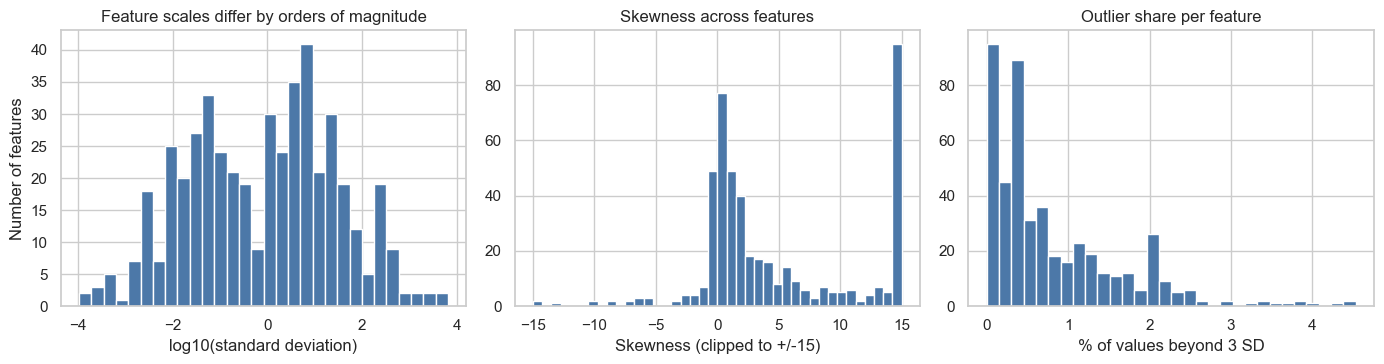

Scale range (std): 1.04e-04 to 6.55e+03
Features with |skew| > 2: 269 of 474


In [27]:
nc = [c for c in X.columns if c not in constant]
desc = X[nc].agg(["mean", "std", "skew"]).T
desc["outlier_share_%"] = ((X[nc] - X[nc].mean()).abs() > 3 * X[nc].std()).mean() * 100

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))

ax[0].hist(np.log10(desc["std"].replace(0, np.nan).dropna()), bins=30, color=PASS_COL, edgecolor="white")
ax[0].set_xlabel("log10(standard deviation)")
ax[0].set_ylabel("Number of features")
ax[0].set_title("Feature scales differ by orders of magnitude")

ax[1].hist(desc["skew"].clip(-15, 15).dropna(), bins=40, color=PASS_COL, edgecolor="white")
ax[1].set_xlabel("Skewness (clipped to +/-15)")
ax[1].set_title("Skewness across features")

ax[2].hist(desc["outlier_share_%"].dropna(), bins=30, color=PASS_COL, edgecolor="white")
ax[2].set_xlabel("% of values beyond 3 SD")
ax[2].set_title("Outlier share per feature")
savefig("05_scale_skew_outliers")

print(f"Scale range (std): {desc['std'].min():.2e} to {desc['std'].max():.2e}")
print(f"Features with |skew| > 2: {(desc['skew'].abs() > 2).sum()} of {len(desc)}")

### CLass balance

0
Pass    1463
Fail     104
Name: count, dtype: int64

Failure rate: 6.64%  |  Imbalance ratio: 14.1 : 1
A model that always predicts 'pass' scores 93.4% accuracy but catches 0 failures.


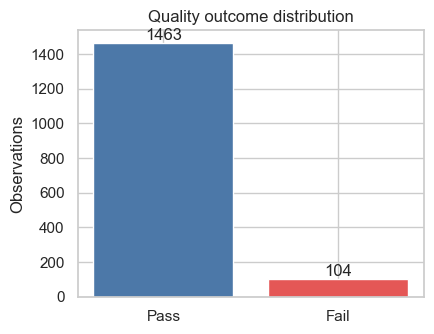

In [28]:
counts = y.value_counts().sort_index()
print(counts.rename({0: "Pass", 1: "Fail"}))
print(f"\nFailure rate: {y.mean() * 100:.2f}%  |  Imbalance ratio: {counts[0] / counts[1]:.1f} : 1")
print(f"A model that always predicts 'pass' scores {(1 - y.mean()) * 100:.1f}% accuracy "
      f"but catches 0 failures.")

fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.bar(["Pass", "Fail"], counts.values, color=[PASS_COL, FAIL_COL])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v}", ha="center", va="bottom")
ax.set_ylabel("Observations")
ax.set_title("Quality outcome distribution")
savefig("06_class_balance")

## 7. Pass vs fail: single-feature signal (training data only)

For each usable feature, the Mann-Whitney U test measures how well that feature alone separates failures from passes. The statistic is converted to a single-feature **AUC** (0.5 = no signal). A rank-based test is used because many sensors are skewed.

Testing hundreds of features at once produces false positives by chance, so p-values are adjusted with the Benjamini-Hochberg false discovery rate (FDR) procedure.

In [29]:
usable_train = [
    c for c in X_train.columns
    if X_train[c].nunique(dropna=True) > 1 and miss_pct_train[c] <= MISSING_THRESHOLD
]

rows = []
for c in usable_train:
    fail_vals = X_train.loc[y_train == 1, c].dropna()
    pass_vals = X_train.loc[y_train == 0, c].dropna()
    if len(fail_vals) < 10 or len(pass_vals) < 10:
        continue
    u, p = stats.mannwhitneyu(fail_vals, pass_vals, alternative="two-sided")
    rows.append((c, u / (len(fail_vals) * len(pass_vals)), p))

uni = pd.DataFrame(rows, columns=["feature", "auc", "p_value"])
uni["strength"] = (uni["auc"] - 0.5).abs()


def benjamini_hochberg(p):
    p = np.asarray(p)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(n)
    out[order] = np.minimum(q, 1)
    return out


uni["q_value"] = benjamini_hochberg(uni["p_value"])
uni = uni.sort_values("strength", ascending=False).reset_index(drop=True)

n_tests = len(uni)
print(f"Features tested: {n_tests}")
print(f"p < 0.05 (raw):            {(uni['p_value'] < 0.05).sum()}   "
      f"(about {0.05 * n_tests:.0f} expected by chance alone)")
print(f"q < 0.05 (FDR-adjusted):   {(uni['q_value'] < 0.05).sum()}")
print(f"Strongest single-feature AUC: {uni['auc'].iloc[0]:.3f}  ({uni['feature'].iloc[0]})")
display(uni.head(10).round(4))

Features tested: 440
p < 0.05 (raw):            71   (about 22 expected by chance alone)
q < 0.05 (FDR-adjusted):   19
Strongest single-feature AUC: 0.728  (59)


,feature,auc,p_value,strength,q_value
0,59,0.7275,0.0000,0.2275,0.0000
1,247,0.6760,0.0000,0.1760,0.0002
2,519,0.6752,0.0000,0.1752,0.0002
3,103,0.6456,0.0000,0.1456,0.0006
4,385,0.6341,0.0002,0.1341,0.0098
5,510,0.6312,0.0000,0.1312,0.0038
6,477,0.6298,0.0001,0.1298,0.0038
7,205,0.6289,0.0001,0.1289,0.0038
8,290,0.6285,0.0001,0.1285,0.0038
9,341,0.6245,0.0001,0.1245,0.0052


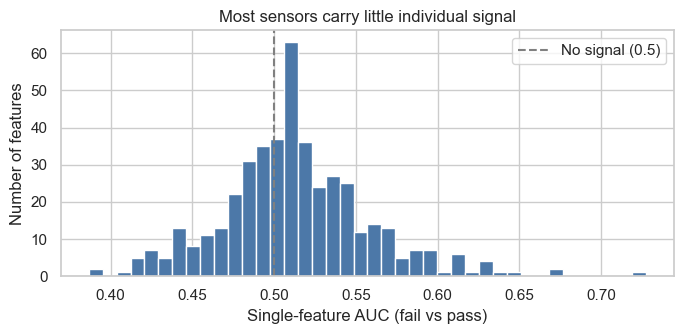

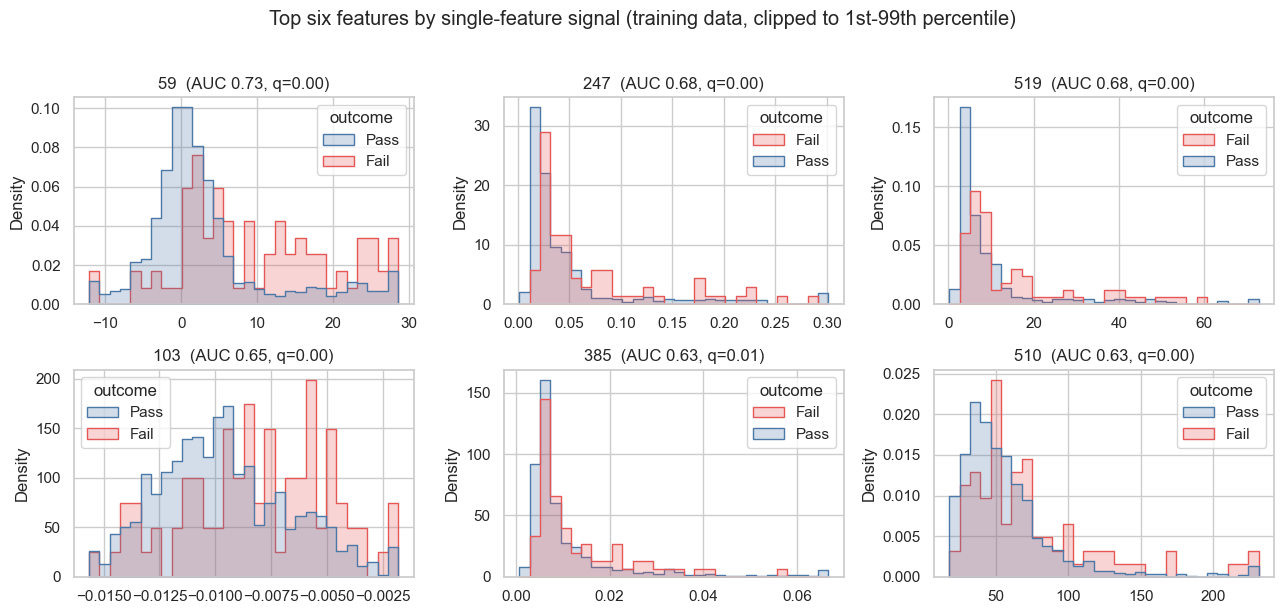

In [30]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(uni["auc"], bins=40, color=PASS_COL, edgecolor="white")
ax.axvline(0.5, color="grey", ls="--", label="No signal (0.5)")
ax.set_xlabel("Single-feature AUC (fail vs pass)")
ax.set_ylabel("Number of features")
ax.set_title("Most sensors carry little individual signal")
ax.legend()
savefig("07_single_feature_auc")

top6 = uni["feature"].head(6).tolist()
outcome = y_train.map({0: "Pass", 1: "Fail"})

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for a, c in zip(axes.ravel(), top6):
    s = X_train[c]
    lo, hi = s.quantile([0.01, 0.99])
    plot_df = pd.DataFrame({"value": s.clip(lo, hi), "outcome": outcome}).dropna()
    sns.histplot(
        data=plot_df, x="value", hue="outcome", stat="density", common_norm=False,
        element="step", bins=30, palette={"Pass": PASS_COL, "Fail": FAIL_COL}, ax=a,
    )
    row = uni[uni["feature"] == c].iloc[0]
    a.set_title(f"{c}  (AUC {row['auc']:.2f}, q={row['q_value']:.2f})")
    a.set_xlabel("")
fig.suptitle("Top six features by single-feature signal (training data, clipped to 1st-99th percentile)", y=1.02)
savefig("07_top_features_by_class")

> **Observation (fill in):** Compare the raw count of p < 0.05 with the number expected by chance, and with the FDR-adjusted count. If few or no features survive FDR correction and the best AUC is near 0.6, the signal is weak and spread thinly, so expect modest model scores. State this plainly in the README.
>
> **Note:** top-feature rankings on ~80 failures are unstable. Do not treat this list as final feature selection; selection must happen inside cross-validation in the modelling notebook.

## 8. Redundancy between features (training data only) 

Feature pairs analysed: 96,580
  |corr| > 0.8: 628 pairs
  |corr| > 0.9: 379 pairs
  |corr| > 0.95: 264 pairs
  |corr| > 0.99: 114 pairs

Features with at least one partner at |corr| > 0.95: 277 of 440


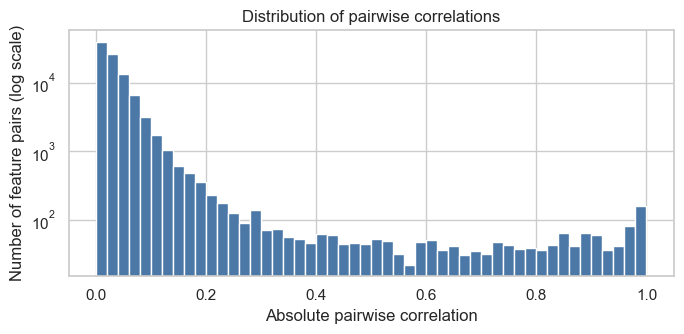

In [31]:
corr = X_train[usable_train].corr()
abs_corr = corr.abs().to_numpy()
pair_vals = abs_corr[np.triu_indices_from(abs_corr, k=1)]
pair_vals = pair_vals[~np.isnan(pair_vals)]

print(f"Feature pairs analysed: {len(pair_vals):,}")
for t in (0.8, 0.9, 0.95, 0.99):
    print(f"  |corr| > {t}: {(pair_vals > t).sum():,} pairs")

has_partner = ((abs_corr > 0.95).sum(axis=1) - 1) > 0  # subtract the diagonal
print(f"\nFeatures with at least one partner at |corr| > 0.95: {has_partner.sum()} of {len(usable_train)}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(pair_vals, bins=50, color=PASS_COL, edgecolor="white")
ax.set_yscale("log")
ax.set_xlabel("Absolute pairwise correlation")
ax.set_ylabel("Number of feature pairs (log scale)")
ax.set_title("Distribution of pairwise correlations")
savefig("08_correlation_distribution")

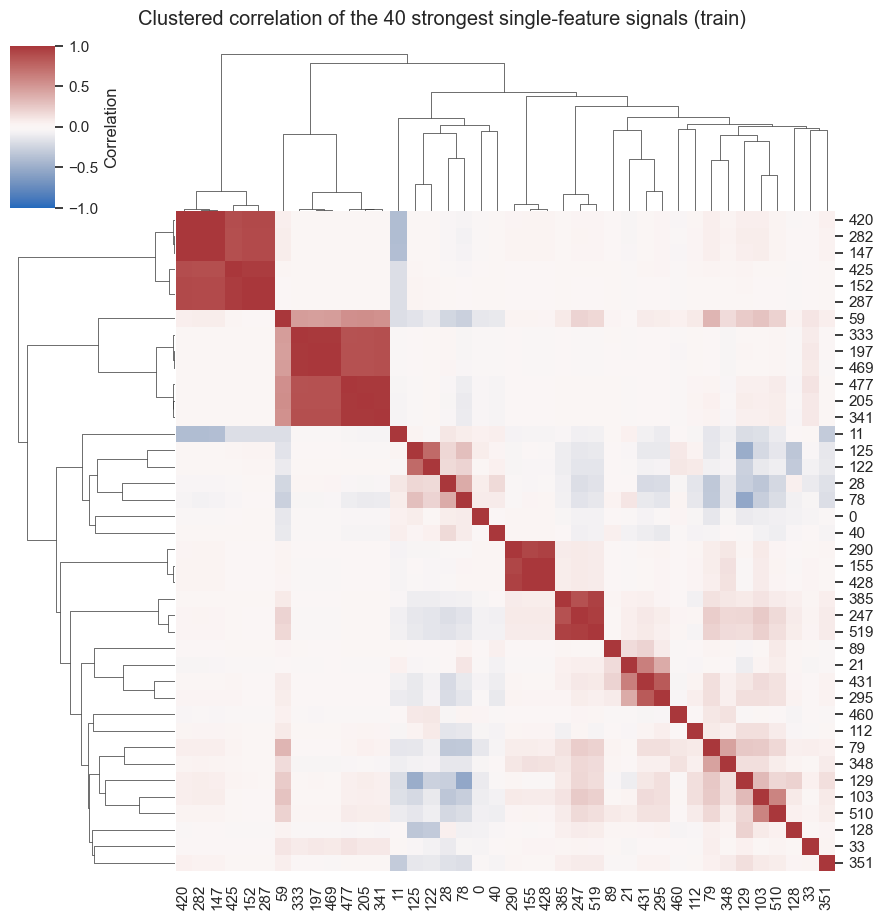

In [32]:
# Clustered heatmap of the 40 features with the strongest single-feature signal
top40 = uni["feature"].head(40).tolist()
g = sns.clustermap(
    X_train[top40].corr().fillna(0), cmap="vlag", center=0, vmin=-1, vmax=1,
    figsize=(9, 9), xticklabels=True, yticklabels=True,
    cbar_kws={"label": "Correlation"},
)
g.fig.suptitle("Clustered correlation of the 40 strongest single-feature signals (train)", y=1.02)
g.savefig(FIG_DIR / "08_correlation_clustermap.png", dpi=150, bbox_inches="tight")
plt.show()

> **Observation (fill in):** Blocks of highly correlated sensors mean many features are redundant. This supports regularised models and feature selection inside the pipeline.

## 9. Dimensionality: PCA (training data only)

Imputation and scaling are fitted on the training data only.

Components needed for 90% of variance: 126  |  95%: 159  (from 440 features)


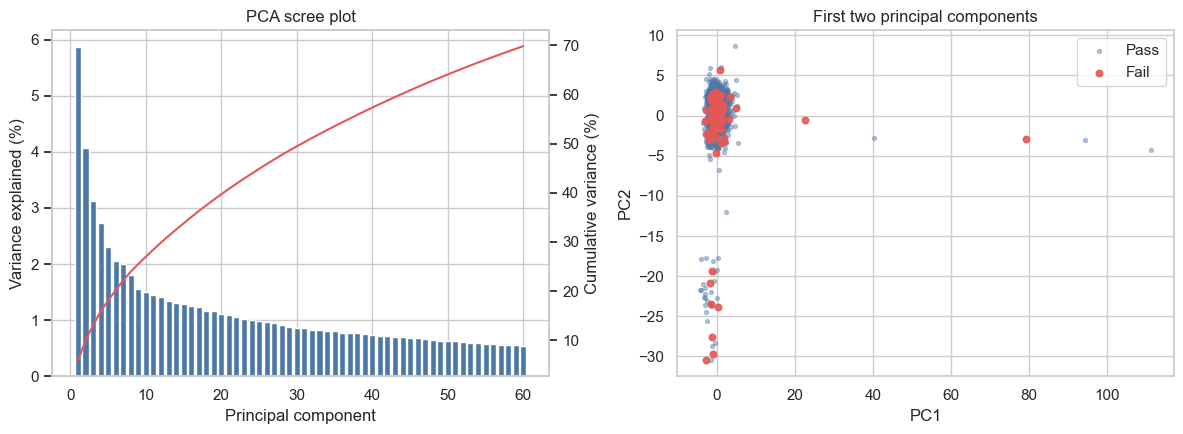

In [33]:
X_imp = SimpleImputer(strategy="median").fit_transform(X_train[usable_train])
X_std = StandardScaler().fit_transform(X_imp)

pca = PCA(random_state=SEED).fit(X_std)
cum = np.cumsum(pca.explained_variance_ratio_)
n90 = int(np.searchsorted(cum, 0.90) + 1)
n95 = int(np.searchsorted(cum, 0.95) + 1)
print(f"Components needed for 90% of variance: {n90}  |  95%: {n95}  (from {len(usable_train)} features)")

Z = pca.transform(X_std)[:, :2]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

k = min(60, len(cum))
ax[0].bar(range(1, k + 1), pca.explained_variance_ratio_[:k] * 100, color=PASS_COL)
ax2 = ax[0].twinx()
ax2.plot(range(1, k + 1), cum[:k] * 100, color=FAIL_COL)
ax2.set_ylabel("Cumulative variance (%)")
ax2.grid(False)
ax[0].set_xlabel("Principal component")
ax[0].set_ylabel("Variance explained (%)")
ax[0].set_title("PCA scree plot")

mask = (y_train == 0).to_numpy()
ax[1].scatter(Z[mask, 0], Z[mask, 1], s=8, alpha=0.4, color=PASS_COL, label="Pass")
ax[1].scatter(Z[~mask, 0], Z[~mask, 1], s=22, alpha=0.9, color=FAIL_COL, label="Fail")
ax[1].set_xlabel("PC1")
ax[1].set_ylabel("PC2")
ax[1].set_title("First two principal components")
ax[1].legend()
savefig("09_pca")

## 10. Drift between train and test

If sensor behaviour shifts over time, performance measured on a random split would be optimistic. Two checks:
- a two-sample Kolmogorov-Smirnov test comparing each feature's train and test distributions
- the rank correlation of each feature with time

Neither uses the target.

In [34]:
ks_rows = []
for c in usable_train:
    a, b = X_train[c].dropna(), X_test[c].dropna()
    if len(b) < 10:
        continue
    stat, p = stats.ks_2samp(a, b)
    ks_rows.append((c, stat, p))
ks = pd.DataFrame(ks_rows, columns=["feature", "ks_stat", "p_value"]).sort_values("ks_stat", ascending=False)

print(f"Features tested: {len(ks)}")
print(f"Train/test distributions differ at p < 0.001: {(ks['p_value'] < 0.001).sum()} features "
      f"({(ks['p_value'] < 0.001).mean() * 100:.0f}%)")


def time_corr(s):
    mask = s.notna().to_numpy()
    if mask.sum() < 30 or s[mask].nunique() < 2:
        return np.nan
    return stats.spearmanr(np.arange(len(s))[mask], s[mask])[0]


rho = X[usable].apply(time_corr).dropna()
print(f"Features with |rank correlation with time| > 0.3: {(rho.abs() > 0.3).sum()} of {len(rho)}")

Features tested: 440
Train/test distributions differ at p < 0.001: 285 features (65%)
Features with |rank correlation with time| > 0.3: 46 of 442


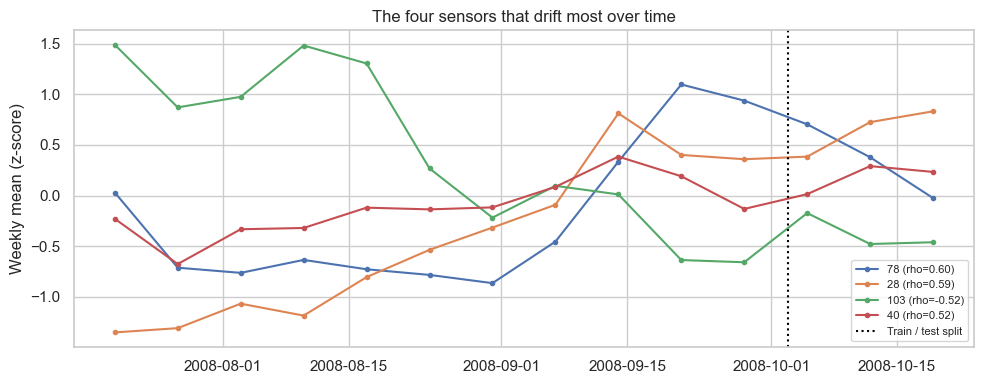

In [35]:
drift_feats = rho.abs().sort_values(ascending=False).head(4).index.tolist()
z = (X[drift_feats] - X[drift_feats].mean()) / X[drift_feats].std()
z.index = pd.DatetimeIndex(ts.values)
weekly_z = z.resample("W").mean()

fig, ax = plt.subplots(figsize=(10, 4))
for c in drift_feats:
    ax.plot(weekly_z.index, weekly_z[c], marker="o", ms=3, label=f"{c} (rho={rho[c]:.2f})")
ax.axvline(ts.iloc[split], color="black", ls=":", label="Train / test split")
ax.set_ylabel("Weekly mean (z-score)")
ax.set_title("The four sensors that drift most over time")
ax.legend(fontsize=8)
savefig("10_sensor_drift")

## Summary

### Input features:

- Total features: 590
- Total observations: 1568
- Overall missing value percentage: 4.54% of all data values
- 538 features out of totl 590 have atleast one missing value
- 41951 data values are missing across 538 features
- No duplicates found at row level

### Target values:
- Quality test passed percentage: 93.36
- Quality test failed percentage: 6.64
- This indicates a significant class imbalance: 
    This imbalance presents a challenge for predictive modelling, as a classifier may achieve high overall accuracy while failing to identify manufacturing defects. Therefore, model evaluation needs to have an emphasis on failure-class precision, recall, F1-score and Precision-Recall AUC rather than relying on accuracy alone.

In [36]:
decisions = pd.DataFrame(
    [
        ("Class imbalance",
         f"{y.mean() * 100:.2f}% failures ({y.sum()} of {len(y)}); {y_test.sum()} failures in test set",
         "Class weights or resampling inside CV only; tune the decision threshold; lead with PR-AUC, recall and precision, not accuracy"),
        ("Missing values",
         f"{(miss_pct > 0).sum()} features have gaps; {(miss_pct > MISSING_THRESHOLD).sum()} exceed {MISSING_THRESHOLD}% missing",
         f"Drop features above {MISSING_THRESHOLD}% missing and median-impute the rest, fitted inside the pipeline"),
        ("Constant features",
         f"{len(constant)} constant, {len(near_constant)} near-constant",
         "Remove with a variance threshold inside the pipeline"),
        ("Scale and skew",
         f"Std spans {desc['std'].min():.1e} to {desc['std'].max():.1e}; {(desc['skew'].abs() > 2).sum()} features with |skew| > 2",
         "Standardise for linear models; consider a robust or quantile transform"),
        ("Weak univariate signal",
         f"Best single-feature AUC {uni['auc'].iloc[0]:.2f}; {(uni['q_value'] < 0.05).sum()} features pass FDR 5%",
         "Expect modest scores; compare against a dummy baseline; do not over-interpret feature rankings"),
        ("Redundancy",
         f"{(pair_vals > 0.95).sum():,} feature pairs with |corr| > 0.95",
         "Regularisation and feature selection inside CV; keep k as a tuned hyperparameter"),
        ("Dimensionality",
         f"{n90} principal components explain 90% of variance (of {len(usable_train)} features)",
         "High-dimensional but compressible; try L1 or tree models and optionally PCA"),
        ("Drift over time",
         f"{(ks['p_value'] < 0.001).sum()} features differ between train and test (KS, p < 0.001)",
         "Use a temporal holdout and report it as the headline estimate; note drift as a limitation"),
    ],
    columns=["Finding", "Evidence", "Modelling decision"],
)

pd.set_option("display.max_colwidth", None)
display(decisions)
decisions.to_csv(FIG_DIR.parent / "eda_decisions.csv", index=False)

,Finding,Evidence,Modelling decision
0,Class imbalance,6.64% failures (104 of 1567); 17 failures in test set,"Class weights or resampling inside CV only; tune the decision threshold; lead with PR-AUC, recall and precision, not accuracy"
1,Missing values,538 features have gaps; 32 exceed 40% missing,"Drop features above 40% missing and median-impute the rest, fitted inside the pipeline"
2,Constant features,"116 constant, 6 near-constant",Remove with a variance threshold inside the pipeline
3,Scale and skew,Std spans 1.0e-04 to 6.6e+03; 269 features with |skew| > 2,Standardise for linear models; consider a robust or quantile transform
4,Weak univariate signal,Best single-feature AUC 0.73; 19 features pass FDR 5%,Expect modest scores; compare against a dummy baseline; do not over-interpret feature rankings
5,Redundancy,264 feature pairs with |corr| > 0.95,Regularisation and feature selection inside CV; keep k as a tuned hyperparameter
6,Dimensionality,126 principal components explain 90% of variance (of 440 features),High-dimensional but compressible; try L1 or tree models and optionally PCA
7,Drift over time,"285 features differ between train and test (KS, p < 0.001)",Use a temporal holdout and report it as the headline estimate; note drift as a limitation
